In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pymongo import MongoClient
from collections import Counter

# -----------------------------
# Config
# -----------------------------
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
MAX_DOCS = None  # set to a number to limit (e.g., 10000)
OUTPUT_DIR = "./figures_tables/metadata_analysis_output"

# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -----------------------------
# Connect and Load Data
# -----------------------------
client = MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

cursor = collection.find({}, {
    "_id": 1,
    "validation_info.checks.metadata_validation": 1
})

data = list(cursor if MAX_DOCS is None else cursor.limit(MAX_DOCS))
client.close()

# -----------------------------
# Flatten Metadata Validation Info
# -----------------------------
rows = []
for doc in data:
    vi = doc.get("validation_info", {})
    mdv = vi.get("checks", {}).get("metadata_validation", {})
    metrics = mdv.get("metrics", {})
    diag = metrics.get("diagnostics", {})

    rows.append({
        "_id": doc.get("_id"),
        "metadata_status": mdv.get("status"),
        "metadata_warning_count": metrics.get("warning_count", 0),
        "metadata_warnings": metrics.get("warnings", []),
        "missing_fields": diag.get("missing_fields", []),
        "date_issue": diag.get("date_issue"),
        "future_date": diag.get("future_date", False),
        "no_chemistry_field": diag.get("no_chemistry_field", False),
        "oa_missing_licenses": diag.get("oa_missing_licenses", []),
    })

df = pd.DataFrame(rows)

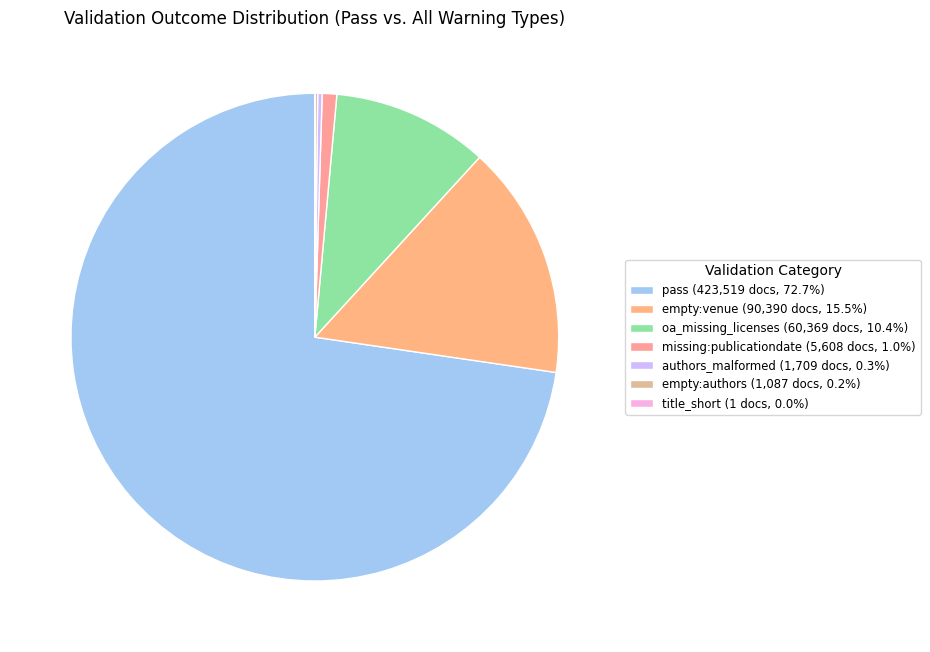

In [2]:
# -----------------------------
# Pie chart: pass vs. all warning types (with full legend)
# -----------------------------

# Function to assign each doc a single category
def classify_doc(row):
    if row["metadata_status"] == "pass":
        return "pass"
    elif row["metadata_status"] == "warn":
        warnings = row.get("metadata_warnings", [])
        return warnings[0] if warnings else "warn:unspecified"
    else:
        return "other"

# Apply classification
df["validation_category"] = df.apply(classify_doc, axis=1)

# Count categories
category_counts = df["validation_category"].value_counts()
total_docs = category_counts.sum()
percentages = category_counts / total_docs * 100

# Legend labels: Category (count docs, percent%)
legend_labels = [
    f"{cat} ({count:,} docs, {pct:.1f}%)"
    for cat, count, pct in zip(category_counts.index, category_counts.values, percentages)
]

# Plot pie chart
fig, ax = plt.subplots(figsize=(9, 8))
wedges, _ = ax.pie(
    category_counts.values,
    labels=None,
    startangle=90,
    colors=sns.color_palette("pastel", n_colors=len(category_counts)),
    wedgeprops={"linewidth": 1, "edgecolor": "white"}
)

# Add all labels to legend
ax.legend(
    wedges,
    legend_labels,
    title="Validation Category",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    fontsize="small"
)

# Final touches
plt.title("Validation Outcome Distribution (Pass vs. All Warning Types)")
plt.tight_layout()

# Save outputs
plt.savefig(
    os.path.join(OUTPUT_DIR, "validation_status_full_pie_legend.png"),
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save raw counts
category_counts.to_csv(os.path.join(OUTPUT_DIR, "validation_status_full_counts.csv"))


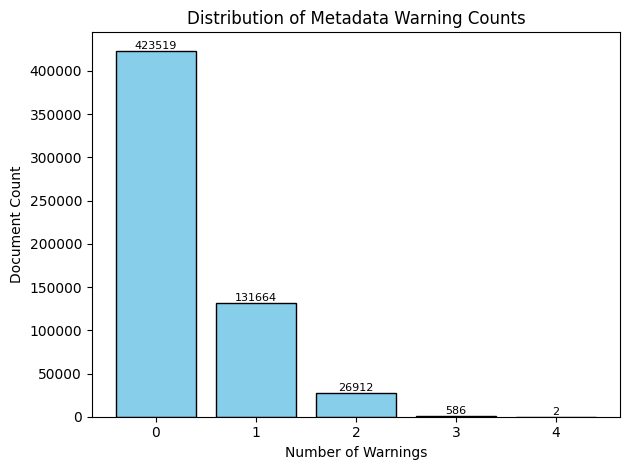

In [3]:
import os
import matplotlib.pyplot as plt

# Count occurrences of each integer warning count
counts = df["metadata_warning_count"].dropna().astype(int).value_counts().sort_index()

# X and Y values
x_vals = counts.index
y_vals = counts.values

# Plot bars
fig, ax = plt.subplots()
bars = ax.bar(x_vals, y_vals, color="skyblue", edgecolor="black")

# Add value labels above each bar
for bar in bars:
    height = bar.get_height()
    if height > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=8
        )

# Labels and formatting
ax.set_title("Distribution of Metadata Warning Counts")
ax.set_xlabel("Number of Warnings")
ax.set_ylabel("Document Count")
ax.set_xticks(x_vals)  # Ensure only integers on x-axis
plt.tight_layout()

# Save and show
plt.savefig(os.path.join(OUTPUT_DIR, "metadata_warning_histogram.png"))
plt.show()
plt.close()


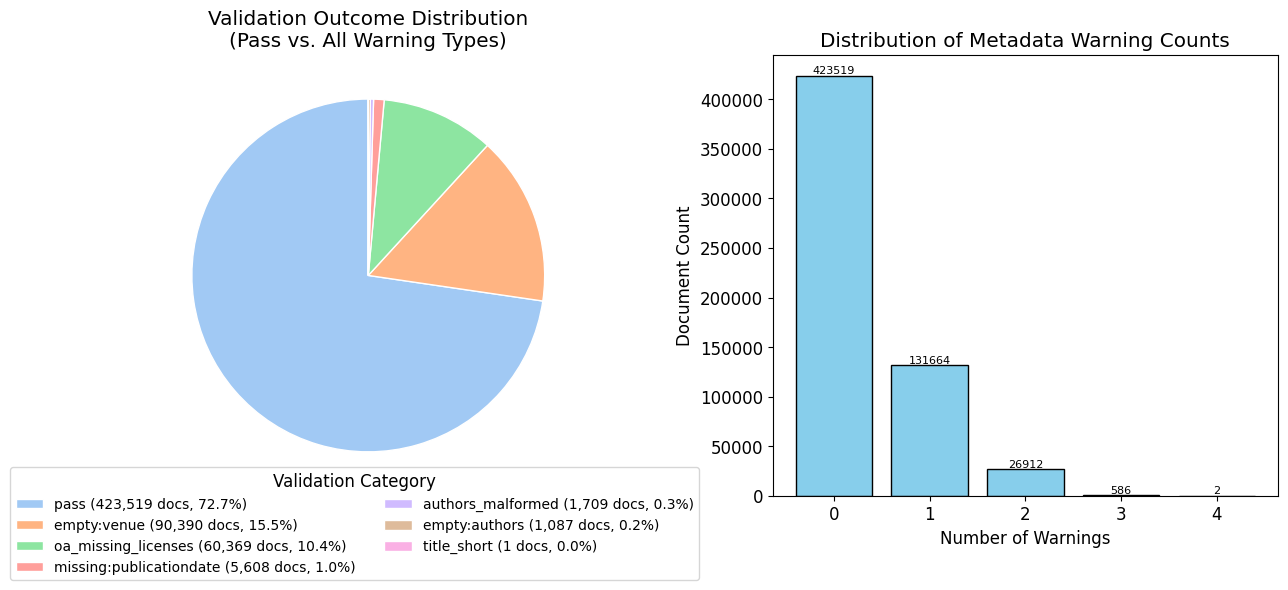

In [24]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams.update({'font.size': 12})  # change 12 to your preferred size

# -----------------------------
# Classification function
# -----------------------------
def classify_doc(row):
    if row["metadata_status"] == "pass":
        return "pass"
    elif row["metadata_status"] == "warn":
        warnings = row.get("metadata_warnings", [])
        return warnings[0] if warnings else "warn:unspecified"
    else:
        return "other"

df["validation_category"] = df.apply(classify_doc, axis=1)

# -----------------------------
# Pie chart data
# -----------------------------
category_counts = df["validation_category"].value_counts()
total_docs = category_counts.sum()
percentages = category_counts / total_docs * 100

legend_labels = [
    f"{cat} ({count:,} docs, {pct:.1f}%)"
    for cat, count, pct in zip(category_counts.index, category_counts.values, percentages)
]

# -----------------------------
# Bar chart data
# -----------------------------
counts = df["metadata_warning_count"].dropna().astype(int).value_counts().sort_index()
x_vals = counts.index
y_vals = counts.values

# -----------------------------
# Combined figure
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1, 1]})

# ----- Pie Chart -----
wedges, _ = axes[0].pie(
    category_counts.values,
    labels=None,
    startangle=90,
    colors=sns.color_palette("pastel", n_colors=len(category_counts)),
    wedgeprops={"linewidth": 1, "edgecolor": "white"}
)
axes[0].set_title("Validation Outcome Distribution\n(Pass vs. All Warning Types)")
axes[0].set_aspect("equal")  # keep it circular and same size

# ----- Bar Chart -----
bars = axes[1].bar(x_vals, y_vals, color="skyblue", edgecolor="black")
for bar in bars:
    height = bar.get_height()
    if height > 0:
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=8
        )
axes[1].set_title("Distribution of Metadata Warning Counts")
axes[1].set_xlabel("Number of Warnings")
axes[1].set_ylabel("Document Count")
axes[1].set_xticks(x_vals)

# ----- Legend at bottom left -----
# Make the legend figure-level but anchored to bottom left
fig.legend(
    wedges,
    legend_labels,
    title="Validation Category",
    loc="lower left",            # anchor point: bottom left
    bbox_to_anchor=(0.05, 0.12),# adjust left-right & up-down position
    fontsize="small",
    ncol=2
)

# Keep both subplots same height and make space for legend
plt.subplots_adjust(bottom=0.25, wspace=0.3)



# Save & show
plt.savefig(os.path.join(OUTPUT_DIR, "combined_same_size_with_bottom_left_legend.png"), bbox_inches="tight")
plt.show()
plt.close()


In [4]:
# 3. Top 10 Documents with Most Warnings
top_docs = df.sort_values("metadata_warning_count", ascending=False)\
             [["_id", "metadata_warning_count"]].head(10)
top_docs.to_csv(os.path.join(OUTPUT_DIR, "top_10_docs.csv"), index=False)

In [5]:

# 5. Table: Most Common Missing Fields
all_missing = df["missing_fields"].dropna().explode()
missing_counts = all_missing.value_counts().reset_index()
missing_counts.columns = ["field", "missing_count"]
missing_counts.to_csv(os.path.join(OUTPUT_DIR, "missing_fields.csv"), index=False)

In [6]:

# 6. Date-related Issues
date_issue_counts = df["date_issue"].value_counts(dropna=False)
future_date_counts = df["future_date"].value_counts(dropna=False)

date_issue_counts.to_csv(os.path.join(OUTPUT_DIR, "date_issues.csv"))
future_date_counts.to_csv(os.path.join(OUTPUT_DIR, "future_date_counts.csv"))

In [7]:
# 7. Chemistry FOS Missing
chem_missing_count = df["no_chemistry_field"].sum()
with open(os.path.join(OUTPUT_DIR, "chemistry_fos_missing.txt"), "w") as f:
    f.write(f"Documents missing Chemistry FOS field: {chem_missing_count}\n")

In [8]:
# 8. Open Access Documents Missing Licenses
oa_missing = df["oa_missing_licenses"].dropna().apply(lambda x: len(x) > 0)
oa_missing_counts = oa_missing.value_counts(dropna=False)
oa_missing_counts.to_csv(os.path.join(OUTPUT_DIR, "oa_missing_licenses.csv"))

# -----------------------------
# Done
# -----------------------------
print("✅ Metadata analysis complete. Outputs saved in 'output/' directory.")


✅ Metadata analysis complete. Outputs saved in 'output/' directory.
